In [24]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
cols = ["date", "symbol", "sector", "close", "adj_close", "volume", "turnover"]
prices = pd.read_csv("nepse_prices.csv", usecols=cols, parse_dates=["date"])
print(prices.shape)
print(prices["date"].min().date(), "to", prices["date"].max().date())
print("Companies:", prices["symbol"].nunique())
prices.head()


(531245, 7)
1995-07-20 to 2026-11-13
Companies: 655


,date,symbol,sector,close,volume,turnover,adj_close
0,1995-07-20,BBC,Trading,2220.0,560.0,0.0,2220.0
1,1995-07-26,BBC,Trading,2442.0,150.0,0.0,2442.0
2,1995-07-30,BBC,Trading,2500.0,200.0,0.0,2500.0
3,1995-08-02,BBC,Trading,2501.0,18.0,0.0,2501.0
4,1995-08-06,BBC,Trading,2500.0,40.0,0.0,2500.0


In [4]:
print(prices["sector"].value_counts())
print(prices.isna().sum())


sector
Hydropower                      127371
Microfinance                     88181
Commercial Bank                  58198
Mutual Fund                      50516
Development Bank                 40664
Finance                          34105
Corporate Debentures             25177
Non-Life Insurance               22102
Life Insurance                   20586
Promoter Share                   14188
Hotel & Tourism                  12635
Manufacturing and Processing     12217
Investment                       11297
Others                            8612
Trading                           4036
Preference Share                   804
Government Bonds                   556
Name: count, dtype: int64
date         0
symbol       0
sector       0
close        0
volume       0
turnover     0
adj_close    0
dtype: int64


In [5]:
non_equity = ["Corporate Debentures", "Government Bonds", "Preference Share",
              "Mutual Fund", "Promoter Share"]
end = prices["date"].max()
start = end - pd.DateOffset(years=3)

w = prices[(prices["date"] > start) & (~prices["sector"].isin(non_equity))].copy()
w = w.sort_values(["symbol", "date"])

days = w.groupby("symbol").size()
keep = days[days >= 500].index
w = w[w["symbol"].isin(keep)].copy()
print("Window:", start.date(), "to", end.date())
print("Stocks kept:", w["symbol"].nunique(), "| rows:", len(w))

Window: 2023-11-13 to 2026-11-13
Stocks kept: 240 | rows: 162636


In [6]:
w["ret"] = np.log(w["adj_close"]).groupby(w["symbol"]).diff()
w["raw_ret"] = np.log(w["close"]).groupby(w["symbol"]).diff()
print("Daily moves bigger than 15%  (raw close):", int((w["raw_ret"].abs() > 0.15).sum()))
print("Daily moves bigger than 15%  (adj close):", int((w["ret"].abs() > 0.15).sum()))
print(w["ret"].describe().round(4))

Daily moves bigger than 15%  (raw close): 62
Daily moves bigger than 15%  (adj close): 20
count    162396.0000
mean          0.0006
std           0.0235
min          -0.1625
25%          -0.0113
50%          -0.0013
75%           0.0096
max           0.1901
Name: ret, dtype: float64


In [7]:
idx = pd.read_csv("../data/indices_close_wide.csv", usecols=["date", "NEPSE Index"],
                  parse_dates=["date"]).dropna()
idx = idx.sort_values("date").set_index("date")
market_ret = np.log(idx["NEPSE Index"]).diff()
w["mret"] = w["date"].map(market_ret)
print(w[["ret", "mret"]].corr().round(2))

       ret  mret
ret   1.00  0.52
mret  0.52  1.00


In [8]:
TRADING_DAYS = 240
rows = []
for sym, g in w.groupby("symbol"):
    r = g["ret"].dropna()
    both = g.dropna(subset=["ret", "mret"])
    cum = g["adj_close"] / g["adj_close"].iloc[0]
    rows.append({
        "symbol": sym,
        "ann_return": r.mean() * TRADING_DAYS,
        "volatility": r.std() * np.sqrt(TRADING_DAYS),
        "max_drawdown": (cum / cum.cummax() - 1).min(),
        "median_turnover": g["turnover"].median(),
        "beta": both["ret"].cov(both["mret"]) / both["mret"].var(),
    })
feat = pd.DataFrame(rows).set_index("symbol")
feat.describe().round(3)

,ann_return,volatility,max_drawdown,median_turnover,beta
count,240.000,240.000,240.000,2.400000e+02,240.000
mean,0.135,0.354,-0.428,1.362456e+07,1.013
std,0.130,0.084,0.143,1.434371e+07,0.211
min,-0.330,0.177,-0.808,1.273959e+06,0.181
25%,0.061,0.290,-0.532,4.899287e+06,0.869
50%,0.133,0.355,-0.407,9.699394e+06,1.016
75%,0.207,0.409,-0.313,1.706385e+07,1.155
max,0.586,0.653,-0.163,1.123635e+08,1.528


Skew before log: 3.4
Skew after log:  0.05


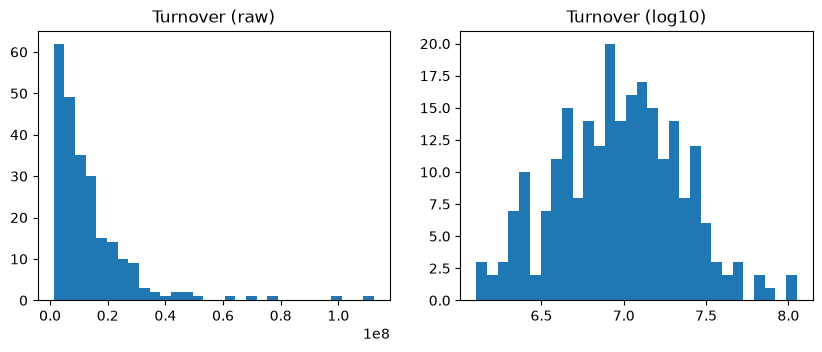

In [9]:
print("Skew before log:", round(feat["median_turnover"].skew(), 2))
feat["log_turnover"] = np.log10(feat["median_turnover"])
print("Skew after log: ", round(feat["log_turnover"].skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(feat["median_turnover"], bins=30); ax[0].set_title("Turnover (raw)")
ax[1].hist(feat["log_turnover"], bins=30);    ax[1].set_title("Turnover (log10)")
plt.show()

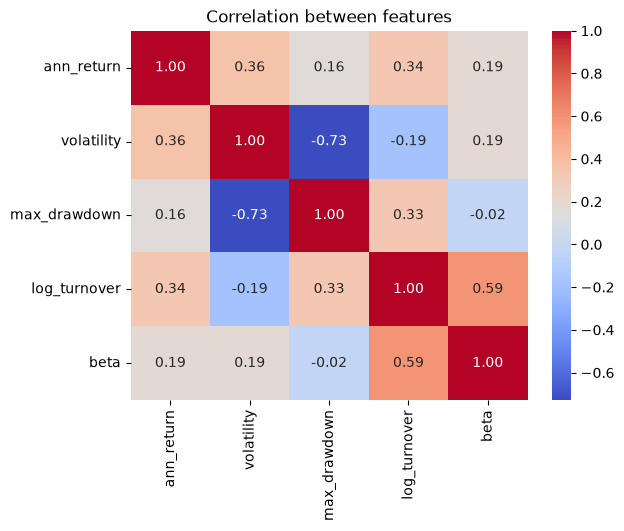

In [10]:
features = ["ann_return", "volatility", "max_drawdown", "log_turnover", "beta"]
sns.heatmap(feat[features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between features")
plt.show()


In [11]:
X = StandardScaler().fit_transform(feat[features])
print(X.shape)

(240, 5)


In [12]:
pca_all = PCA(random_state=1).fit(X)
print("Variance by component:", pca_all.explained_variance_ratio_.round(2))
pca = PCA(n_components=3, random_state=1)
X_pca = pca.fit_transform(X)
print("Kept with 3 components:", pca.explained_variance_ratio_.sum().round(2))

Variance by component: [0.38 0.35 0.18 0.06 0.02]
Kept with 3 components: 0.92


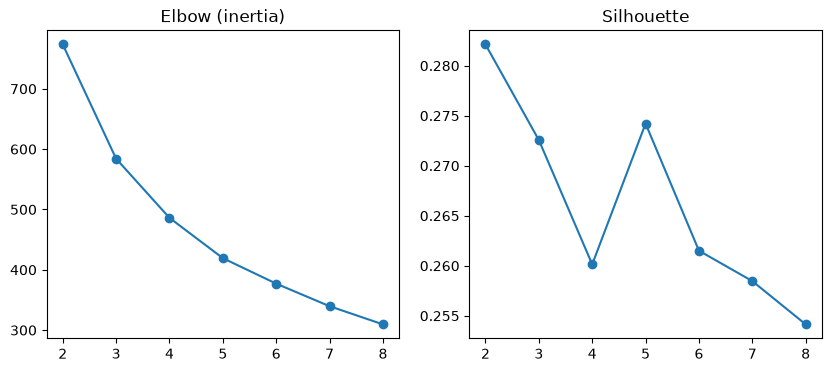

2 0.282
3 0.273
4 0.26
5 0.274
6 0.262
7 0.258
8 0.254


In [13]:
inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=1).fit(X_pca)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_pca, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette")
plt.show()
for k, s in zip(ks, sil):
    print(k, round(s, 3))

In [14]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(X_pca)
feat["Cluster"] = kmeans.labels_
print(feat["Cluster"].value_counts().sort_index())

Cluster
0    71
1    53
2    56
3    60
Name: count, dtype: int64


In [15]:
profile = feat.groupby("Cluster")[features].median().round(2)
profile["Size"] = feat["Cluster"].value_counts().sort_index()
profile

,ann_return,volatility,max_drawdown,log_turnover,beta,Size
Cluster,,,,,,
0,0.07,0.27,-0.33,7.04,0.95,71
1,0.09,0.37,-0.49,6.50,0.80,53
2,0.15,0.42,-0.59,6.94,1.12,56
3,0.22,0.36,-0.32,7.33,1.19,60


In [18]:
comp = pd.read_csv("companies.csv").set_index("symbol")
div = pd.read_csv("dividends.csv")
last3 = (div.sort_values("fiscal_year", ascending=False)
            .groupby("symbol").head(3)
            .groupby("symbol")["total_pct"].mean())

feat["sector"] = comp["sector"]
feat["market_cap_bn"] = comp["market_cap"] / 1e9
feat["avg_dividend_pct"] = last3

print(feat.groupby("Cluster")[["market_cap_bn", "avg_dividend_pct"]].median().round(1))
print(pd.crosstab(feat["Cluster"], feat["sector"]))

         market_cap_bn  avg_dividend_pct
Cluster                                 
0                 21.7              12.5
1                  3.0              15.0
2                  3.7               9.2
3                  9.8               8.7
sector   Commercial Bank  Development Bank  Finance  Hotel & Tourism  \
Cluster                                                                
0                     15                 4        1                1   
1                      0                 0        0                3   
2                      0                 5        9                1   
3                      4                 6        4                1   

sector   Hydropower  Investment  Life Insurance  Manufacturing and Processing  \
Cluster                                                                         
0                 5           1              12                             2   
1                15           1               0                             2 

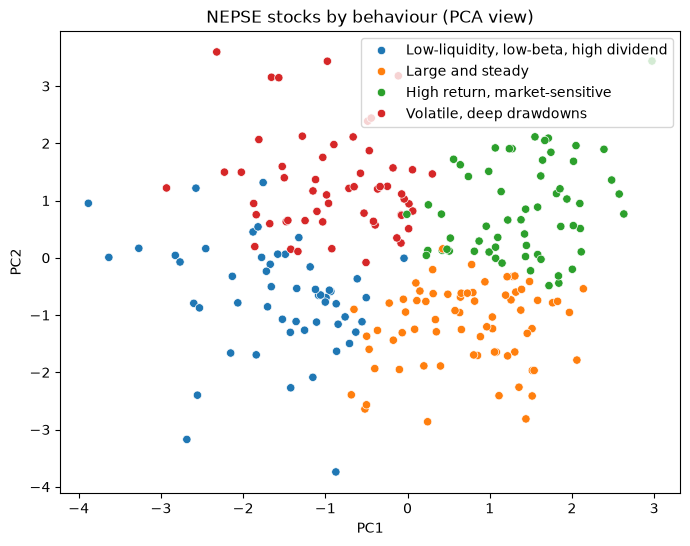

In [19]:
names = {0: "Large and steady", 1: "Low-liquidity, low-beta, high dividend",
         2: "Volatile, deep drawdowns", 3: "High return, market-sensitive"}
feat["Segment"] = feat["Cluster"].map(names)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=feat["Segment"].values, palette="tab10")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("NEPSE stocks by behaviour (PCA view)")
plt.show()

In [21]:
for seg, g in feat.groupby("Segment"):
    top = g.sort_values("market_cap_bn", ascending=False).head(5).index.tolist()
    print(f"{seg}: {top}")

High return, market-sensitive: ['NRIC', 'LSL', 'SBL', 'SHL', 'HIDCL']
Large and steady: ['NTC', 'NABIL', 'CIT', 'GBIME', 'EBL']
Low-liquidity, low-beta, high dividend: ['BBC', 'UNL', 'TRH', 'BNT', 'NLG']
Volatile, deep drawdowns: ['SMHL', 'HATHY', 'RHPL', 'PHCL', 'CITY']


In [22]:
feat.to_csv("nepse_stock_segments.csv")
print(pd.read_csv("nepse_stock_segments.csv").shape)

(240, 12)


In [23]:
scaler = StandardScaler().fit(feat[features])
new = pd.DataFrame([{"ann_return": 0.20, "volatility": 0.35, "max_drawdown": -0.30,
                     "log_turnover": 7.3, "beta": 1.2}])
c = kmeans.predict(pca.transform(scaler.transform(new[features])))[0]
print("New stock falls in:", names[c])

New stock falls in: High return, market-sensitive
